[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/Challenge1_ParameterEstimation.ipynb)

# Challenge 1: From kinetic data to reactor design

Each part of this notebook has a different level of guidance:

1. **Example**: fully worked. Run it and read it; it shows all the PharmaPy syntax you will need.
2. **Guided**: fill in the lines marked `# <-- COMPLETE THIS`.
3. **Unguided**: you get the task, the math and the syntax of the PharmaPy pieces; you write the code.

The plotting helpers in `workshop_utils.py` are given, so that everyone's figures look the same and results are easy to compare. The [SyntaxExamples notebook](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/SyntaxExamples.ipynb) has small runnable examples of every PharmaPy object.

Rough timing: Example 10 min, Guided 15 min, Unguided 20 min, questions 5 min.

## The system

Four reactions take place in an isothermal batch reactor:

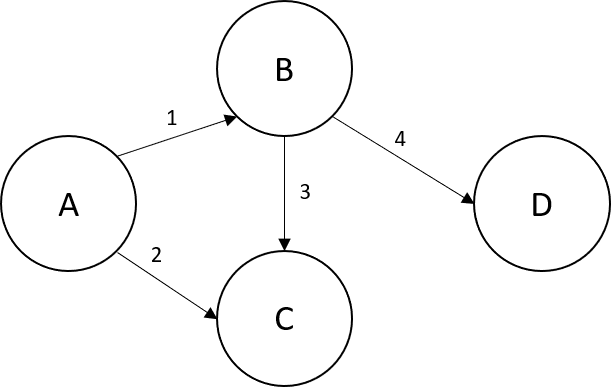

$$ \frac{dC_j}{dt} = \sum_{i=1}^4 \nu_{i, j} r_i, \qquad r_i = k_i \prod_{k \in \mathcal{R}_i} C_k, \qquad k_i = A_i \exp \left(-\frac{E_i}{RT} \right) $$

with $j \in \{A, B, C, D\}$ (all reactions are first order). Five isothermal experiments (673 to 773 K) measured the concentrations of **B and C** over time. The goal is to estimate $A_i$ and $E_i$ from these data (Parts 1 and 2), and then to use them to design the reactor (Part 3).

**Running on Google Colab?** Run the next cell first. It installs PharmaPy and puts this notebook's data files and `workshop_utils.py` on the Colab machine (about half a minute). Run it again whenever the runtime restarts. To keep your work, use *File → Save a copy in Drive*. On your own computer the cell skips the install and only unpacks the files.

In [ ]:
# @title Colab setup: run this cell first { display-mode: "form" }
# Installs PharmaPy and unpacks workshop_utils.py and data/ into the working
# directory. Run it again after a runtime restart or a factory reset.
import base64, importlib.metadata, importlib.util, io, os, subprocess, sys, zipfile

if 'google.colab' in sys.modules or importlib.util.find_spec('PharmaPy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pharmapy-org>=0.3.1'], check=True)

_FILES = (
    '...'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FILES))) as archive:
    archive.extractall('.')
importlib.invalidate_caches()

try:
    _version = importlib.metadata.version('pharmapy-org')
except importlib.metadata.PackageNotFoundError:   # a development install of PharmaPy
    _version = '(development install)'
print('PharmaPy', _version, '- workshop files ready in', os.getcwd())

## Setup (given)

In [ ]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import linregress, t as t_dist

from PharmaPy.Phases_Refactored import LiquidPhase
from PharmaPy.Kinetics import RxnKinetics
from PharmaPy.Streams_Refactored import LiquidStream
from PharmaPy.Reactors_Refactored import BatchReactor, ContinuousReactor
from PharmaPy.ProcessControl_Refactored import SimpleTemperatureController, ContinuousVesselController
from PharmaPy.IntegratorBackends import ScipyBackend

from workshop_utils import (plot_concentrations, plot_fit, plot_arrhenius, plot_intervals,
                            plot_correlation)

PATH_PURE = 'data/pure_components_ziegler.json'   # species: A, B, C, D, solvent
RXNS = ['A --> B', 'A --> C', 'B --> C', 'B --> D']
TEMPS = [673, 698, 723, 748, 773]                 # K, one experiment each
R_GAS = 8.314                                     # J/(mol K)

with open('data/ziegler_conc_init.json') as f:
    C_INIT = json.load(f)    # initial concentrations (mol/L, all 5 species) per experiment: '673K', ...


def load_data(temp):
    """Measured data at temp (K): sampling times (s) and concentrations of B and C (mol/L)."""
    data = np.genfromtxt('data/ziegler_data_%iK.csv' % temp, delimiter=',')
    return data[:, 0], data[:, 1:]


print(C_INIT['673K'])

---
# Part 1 — Example: simulate and fit one experiment

A PharmaPy simulation is assembled from a few objects, always in the same order:

1. the **unit** (`BatchReactor`), with its own **integrator** (`ScipyBackend`, a wrapper of `scipy.integrate.solve_ivp`). `isothermal=True` keeps the temperature of the liquid (no energy balance);
2. the **phase** loaded into it (`LiquidPhase`: property file, temperature, composition and an amount, here 1 L);
3. the **kinetics** (`RxnKinetics`: reactions as strings, $A_i$ and $E_i$), attached *after* the phase;
4. `solve_unit(...)`, after which everything is in `reactor.result`.

In [ ]:
kin = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=[0.1] * 4, ea_params=[0] * 4)   # E = 0, so k_i = A_i = 0.1 1/s

reactor = BatchReactor(integrator=ScipyBackend(), isothermal=True)
reactor.Phases = LiquidPhase(PATH_PURE, temp=673, mole_conc=C_INIT['673K'], vol=1e-3, name_solv='solvent')
reactor.RxnKinetics = kin
reactor.solve_unit(runtime=120, verbose=False)

print(reactor.result)    # lists every field of the result

`result.time` holds the times (s) and `result.mole_conc_liquid0` the concentrations (mol/L), one column per species (A, B, C, D, solvent):

In [ ]:
plot_concentrations(reactor.result.time, reactor.result.mole_conc_liquid0, title='673 K, $k_i$ = 0.1 1/s')
plt.show()

### A reusable simulation function

To compare with data we will simulate many times, so we wrap the four steps in a function:

* a **new** reactor is built for every call (calling `solve_unit` again on the same reactor *continues* the integration);
* `solve_unit(time_grid=...)` needs strictly increasing times, and some datasets have replicate samples, so we solve on the unique times and interpolate back;
* `ScipyBackend(method='LSODA', ...)` with tight tolerances is fast for this system and gives accurate finite-difference gradients.

In [ ]:
def simulate(kinetics, t_vals, temp, conc_init):
    """Isothermal batch reactor. Concentrations (mol/L) at t_vals, one column per species."""
    reactor = BatchReactor(integrator=ScipyBackend(method='LSODA', options={'atol': 1e-10, 'rtol': 1e-8}),
                           isothermal=True)
    reactor.Phases = LiquidPhase(PATH_PURE, temp=temp, mole_conc=conc_init, vol=1e-3, name_solv='solvent')
    reactor.RxnKinetics = kinetics
    reactor.solve_unit(time_grid=np.unique(t_vals), verbose=False)

    res = reactor.result
    return np.column_stack([np.interp(t_vals, res.time, conc) for conc in res.mole_conc_liquid0.T])

### Fitting one experiment

At a single temperature only the four $k_i$ matter. We estimate $\theta = \ln k_i$ (logarithms keep the parameters of order one and $k_i$ positive) by minimizing

$$ SSE(\theta) = \sum_{t} \sum_{j \in \{B, C\}} \left( C_j^{model}(t; \theta) - C_j^{data}(t) \right)^2 $$

with L-BFGS-B. The bounds $-12 \le \ln k_i \le 3$ keep the optimizer away from huge rate constants, which make the ODEs very stiff and slow. B and C are columns 1 and 2 of the model output.

In [ ]:
t_exp, c_exp = load_data(673)


def sse_673(ln_k):
    kin = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=np.exp(ln_k), ea_params=[0] * 4)
    c_model = simulate(kin, t_exp, 673, C_INIT['673K'])
    return np.sum((c_model[:, [1, 2]] - c_exp)**2)


tic = time.perf_counter()
fit_673 = minimize(sse_673, x0=np.log([0.1] * 4), method='L-BFGS-B', bounds=[(-12, 3)] * 4,
                   options={'eps': 1e-6})
print('SSE %.3e after %i simulations (%.1f s)' % (fit_673.fun, fit_673.nfev, time.perf_counter() - tic))
print('ln k =', fit_673.x.round(3))

t_fine = np.linspace(0, t_exp[-1], 100)
kin_fit = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=np.exp(fit_673.x), ea_params=[0] * 4)
plot_fit(t_exp, c_exp, t_fine, simulate(kin_fit, t_fine, 673, C_INIT['673K']), title='673 K',
         c_seed=simulate(kin, t_fine, 673, C_INIT['673K']))   # dashed: the initial guess
plt.show()

---
# Part 2 — Guided: all temperatures and the Arrhenius plot

Each experiment informs the four $k_i$ at its own temperature. Fit $\ln k_i$ for every temperature as in Part 1 (start from the 673 K estimate), then estimate $A_i$ and $E_i$ from the linearized Arrhenius law

$$ \ln k_i = \ln A_i - \frac{E_i}{R} \cdot \frac{1}{T} $$

by linear regression of $\ln k_i$ on $1/T$.

In [ ]:
LNK_BOUNDS = [(-12, 3)] * 4


def sse_isothermal(ln_k, temp):
    """SSE of the experiment at temp (K), for k_i = exp(ln_k) (E = 0 at a single temperature)."""
    t_exp, c_exp = load_data(temp)
    kin = ...  # <-- COMPLETE THIS: kinetics with k_params = exp(ln_k) and ea_params = [0] * 4
    c_model = ...  # <-- COMPLETE THIS: model concentrations at the measured times (initial concentrations: C_INIT['%iK' % temp])
    return ...  # <-- COMPLETE THIS: SSE over B and C (model columns 1 and 2)


ln_k_fit = {}
fig, axes = plt.subplots(1, len(TEMPS), figsize=(18, 3.5))
tic = time.perf_counter()
for temp, ax in zip(TEMPS, axes):
    fit = ...  # <-- COMPLETE THIS: fit ln k at this temperature (seed fit_673.x, args=(temp,), L-BFGS-B with LNK_BOUNDS and options={'eps': 1e-6})
    ln_k_fit[temp] = fit.x

    t_exp, c_exp = load_data(temp)
    t_fine = np.linspace(0, t_exp[-1], 100)
    kin_T = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=np.exp(fit.x), ea_params=[0] * 4)
    plot_fit(t_exp, c_exp, t_fine, simulate(kin_T, t_fine, temp, C_INIT['%iK' % temp]), ax=ax, title='%i K' % temp)
fig.tight_layout()
plt.show()
print('total fitting time: %.0f s' % (time.perf_counter() - tic))

ln_k_table = pd.DataFrame(ln_k_fit, index=['ln k_%i' % (i + 1) for i in range(4)]).T
print(ln_k_table.round(3))

In [ ]:
ln_A, Ea_R = [], []
for i in range(4):
    reg = ...  # <-- COMPLETE THIS: linear regression of ln k_i (column i of ln_k_table) on 1/T
    ...  # <-- COMPLETE THIS: ln A_i is the intercept
    ...  # <-- COMPLETE THIS: E_i / R is minus the slope

plot_arrhenius(TEMPS, ln_k_table.values, ln_A, Ea_R, RXNS)

arrhenius_2stage = pd.DataFrame({'ln A': ln_A, 'E (kJ/mol)': np.array(Ea_R) * R_GAS / 1000}, index=RXNS)
print(arrhenius_2stage.round(2))

---
# Part 3 — Unguided: use your kinetics to design the reactor

Suppose the intermediate **B** is the valuable product (C and D are by-products). Use the kinetics you fitted in Part 2 to decide how to run the reactor.

**Constraints.** The equipment holds the reacting material for **20 s**: that is the batch time, or the residence time of a continuous reactor. The feed is pure A at 1 mol/L, and the temperature must stay within the range of the experiments, 673-773 K (the kinetics are not validated outside it).

**Tasks**
* **(a) Batch.** Find the constant temperature that maximizes the concentration of B at the end of the 20 s batch,

$$ \max_{673\ \mathrm{K} \,\le\, T \,\le\, 773\ \mathrm{K}} \; C_B(t = 20\ \mathrm{s};\ T) $$

and plot $C_B(20\ \mathrm{s})$ against $T$ and the concentration profiles at the optimum.
* **(b) CSTR.** Would a continuous stirred tank with the same 20 s residence time do better? Maximize its steady-state outlet concentration of B over $T$, and compare it with (a) on one plot.

Use the parameters of Part 2: $A_i = e^{\ln A_i}$ (`np.exp(ln_A)`) and $E_i = R \cdot (E_i/R)$ (`R_GAS * np.array(Ea_R)`), with the plain Arrhenius law.

**Syntax you need**
```python
kin = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=A_fit, ea_params=E_fit)   # A_i and E_i (J/mol)

# batch reactor following a temperature function f(t) in K (a constant: lambda t: T)
reactor = BatchReactor(integrator=ScipyBackend(method='LSODA', options={'atol': 1e-10, 'rtol': 1e-8}),
                       controller=SimpleTemperatureController(temp_func=f))
reactor.Phases = LiquidPhase(PATH_PURE, temp=f(0), mole_conc=C_FEED, vol=1e-3, name_solv='solvent')
reactor.RxnKinetics = kin
reactor.solve_unit(time_grid=np.linspace(0, T_HOLD, 61), verbose=False)

# CSTR at constant T: starts full of solvent, fed with C_FEED at vol_flow = V / tau
cstr = ContinuousReactor(integrator=ScipyBackend(...), controller=ContinuousVesselController(temp_func=lambda t: T))
cstr.Phases = LiquidPhase(PATH_PURE, temp=T, mole_conc=[0, 0, 0, 0, 0], vol=1e-3, name_solv='solvent')
cstr.RxnKinetics = kin
cstr.Inlet = LiquidStream(PATH_PURE, temp=T, vol_flow=1e-3 / tau, mole_conc=C_FEED, name_solv='solvent')
cstr.solve_unit(time_grid=np.linspace(0, 8 * tau, 41), verbose=False)    # 8 residence times: steady state

unit.result.mole_conc_liquid0[-1, 1]                                      # C_B at the last time
minimize_scalar(f, bounds=T_RANGE, method='bounded')
```
Plotting helper: `plot_concentrations(time, conc, ax=None, title=None)`. Each simulation takes well under a second.

In [ ]:
T_HOLD = 20.0               # s: batch time, and residence time of the CSTR
C_FEED = [1, 0, 0, 0, 0]    # mol/L: pure A
T_RANGE = (673, 773)        # K: range of the experiments

In [ ]:
# <-- COMPLETE THIS: your code: the fitted kinetics and a batch reactor that follows a temperature function
...

In [ ]:
# <-- COMPLETE THIS: your code: (a) the best constant temperature of the 20 s batch
...

In [ ]:
# <-- COMPLETE THIS: your code: (b) a CSTR with the same 20 s residence time, compared with the batch
...

---
## Questions to think about

**1.** In (a) the best temperature lies inside the allowed range. Why is neither the hottest nor the coldest temperature best for a 20 s batch? What would happen to the best temperature if the batch time were free?

**Your answer:**



**2.** Why does the CSTR give less B than the batch with the same holding time?

**Your answer:**



**3.** Which of your fitted parameters would you check before trusting this design, and why? (Look at your Arrhenius plot from Part 2.)

**Your answer:**



---
## If you finish early

**A. All experiments at once, with confidence intervals.** Estimate the eight Arrhenius parameters from all five experiments simultaneously and compute their 95 % confidence intervals and correlations. Fitting $\ln A_i$ and $E_i$ directly is badly conditioned, so use the *reformulated* Arrhenius law of `RxnKinetics`, centered at $T_{ref}$ = mean temperature of the experiments:

$$ k_i(T) = \exp\left[\varphi_{1,i} + e^{\varphi_{2,i}} \left( \frac{1}{T_{ref}} - \frac{1}{T} \right)\right], \qquad \varphi_{1,i} = \ln A_i - \frac{E_i}{R\,T_{ref}}, \qquad \varphi_{2,i} = \ln \frac{E_i}{R} $$

Stack the residuals $C^{model} - C^{data}$ of B and C of all experiments in one vector $r(\theta)$, $\theta = [\varphi_{1,1..4}, \varphi_{2,1..4}]$, and minimize $SSE = r^T r$ (L-BFGS-B, about a minute). With the Jacobian $J_{kq} = \partial r_k / \partial \theta_q$ at $\hat\theta$ (forward differences, step $10^{-5}\max(1, |\hat\theta_q|)$):

$$ s^2 = \frac{SSE(\hat\theta)}{n - p}, \qquad \mathrm{Cov} = s^2 (J^T J)^{-1}, \qquad \hat\theta_q \pm t_{0.975,\, n-p} \sqrt{\mathrm{Cov}_{qq}}, \qquad \mathrm{Corr}_{qr} = \frac{\mathrm{Cov}_{qr}}{\sqrt{\mathrm{Cov}_{qq}\,\mathrm{Cov}_{rr}}} $$

Then transform back ($E_i = R\, e^{\varphi_{2,i}}$, $\ln A_i = \varphi_{1,i} + e^{\varphi_{2,i}} / T_{ref}$) and re-run Part 3 (a) with the new parameters. Which reaction is least well determined, and does the reactor design change?

```python
kin = RxnKinetics(PATH_PURE, rxn_list=RXNS, k_params=A_seed, ea_params=Ea_seed,   # A_i (pre-exponential!) and E_i (J/mol)
                  reformulate_kin=True, temp_ref=T_REF)
theta0 = kin.concat_params()     # the parameter vector [phi_1,1..4, phi_2,1..4] of these seeds
kin.name_params                  # their names (LaTeX strings), same order
kin.set_params(theta)            # load a parameter vector into the kinetics
t_dist.ppf(0.975, dof)           # Student-t quantile
```
Plotting helpers: `plot_intervals(names, estimate, half_width)`, `plot_correlation(corr, names)`.

In [ ]:
# <-- COMPLETE THIS: your code: seeds, residual function and the simultaneous fit; plot the fit of every experiment
...

In [ ]:
# <-- COMPLETE THIS: your code: Jacobian by finite differences, covariance, 95 % confidence intervals and correlation matrix
...

In [ ]:
# <-- COMPLETE THIS: your code: back to ln A_i and E_i, compared with Part 2
...

In [ ]:
# <-- COMPLETE THIS: your code: Part 3 (a) again, with the parameters of the simultaneous fit
...

**B. A temperature ramp.** Can the batch do better with a temperature that changes in time, e.g. a linear ramp `lambda t: np.interp(t, [0, T_HOLD], [T_start, T_end])` with both temperatures within 673-773 K? Optimize $(T_{start}, T_{end})$ with Nelder-Mead and compare with (a).

In [ ]:
# <-- COMPLETE THIS: your code: a linear temperature ramp for the batch
...

**Your answer:**



**C. Design the next experiment.** You can run one more isothermal experiment, with the same sampling times and initial concentrations as the 673 K experiment, at any temperature between 650 and 800 K. Which temperature adds the most information? Use the **D-optimal** criterion (needs the Jacobian of extension A): maximize $\log\det(J^TJ + J_T^TJ_T)$, where $J_T$ is the Jacobian of the *predicted* B and C of the new experiment at $\hat\theta$.

In [ ]:
# <-- COMPLETE THIS: your code: D-optimal temperature of the next experiment
...